# The Chen–LeBrun–Weber extremal metric, numerically

CP² # 2CP̄² in the bilaterally symmetric Kähler class that is critical for the Calabi functional (notebook 01, §8). There the extremal metric g is Bach-flat, so s⁻²g is Einstein (Chen–LeBrun–Weber 2008).

**Method** (`extremal.solver`). u = u_G + h with h a polynomial of degree ≤ d, chosen to minimize Donaldson's convex functional F(u) = −∫ log det Hess u dμ + 2 L_A(u) by Newton's method. Its critical points are exactly the solutions of Abreu's equation S(u) = A_ext. The basis is orthonormal on the polygon. Everything below is checked through `ToricMetric`, which computes curvature from fourth derivatives, independently of the solver.

**Comparison.** Hall–Murphy (arXiv:1407.1272) computed the same metric by minimizing ∫(S − A)² with conjugate gradients over monomials. We use their coordinates, so their numbers can be compared directly.

In [1]:
%matplotlib inline
import time
from fractions import Fraction
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from extremal import Polygon, ToricMetric, viz
from extremal.quadrature import polygon_quadrature, integrate_numeric
from extremal.solver import ExtremalSolver

## 1. The polygon

Hall–Murphy's pentagon: 1 + x₁, 1 + x₂, a − 1 − x₁, a − 1 − x₂, a − 1 − x₁ − x₂ ≥ 0. In CLW's notation, a = 1 + x with x = ε/β, and a = 2 is the class c₁. The critical class is x₀, the unique positive root of an irreducible degree-10 polynomial (notebook 01, §8). The solver works in floating point, so a rational approximation of a within 10⁻¹⁵ is harmless.

a = 1 + x₀ = 1.9577128051877618607    using 1.957712805187762
A_ext = 1.943290163721 + -0.423189120330 (x + y)    (Riemannian s = 2 A_ext)


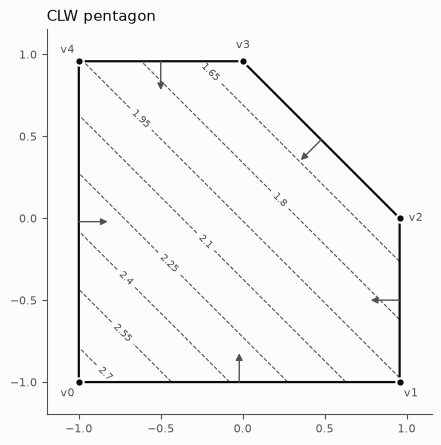

In [2]:
xx = sp.Symbol('x')
minpoly = sp.Poly(xx**10 + 15*xx**9 + 96*xx**8 + 336*xx**7 + 680*xx**6 + 720*xx**5 + 120*xx**4
                  - 624*xx**3 - 708*xx**2 - 300*xx - 48, xx)
x0 = [r for r in minpoly.real_roots() if r > 0][0]
a = Fraction(str(sp.N(1 + x0, 30))).limit_denominator(10**15)
print('a = 1 + x₀ =', sp.N(1 + x0, 20), '   using', float(a))

P = Polygon([(-1, -1), (a - 1, -1), (a - 1, 0), (0, a - 1), (-1, a - 1)], name='CLW pentagon')
A = P.A_ext
print('A_ext = %.12f + %.12f (x + y)' % (float(A.c0), float(A.c1)), '   (Riemannian s = 2 A_ext)')
ax = viz.plot_polygon(P, labels=False)
viz.plot_A_ext(P, ax=ax);

## 2. Solving at several degrees

Unknowns: (d+1)(d+2)/2 − 3. The defect S − A_ext is measured at quadrature nodes at distance ≥ 0.01 from ∂P (closer in, the fourth-derivative evaluation itself loses digits). Hall–Murphy's measure is the area-normalized L² norm of s − s_ext, with s = 2S, i.e. twice our L².

In [3]:
degrees = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24]
results = {}
print(f"{'d':>3} {'unknowns':>8} {'Newton':>6} {'time':>7}  {'sup |S − A|':>11} {'L² (S − A)':>11} {'HM measure':>11}")
for d in degrees:
    t = time.perf_counter()
    solver = ExtremalSolver(P, degree=d)
    r = solver.solve()
    r.defect_ = r.defect()
    results[d] = r
    print(f"{d:>3} {solver.free.size:>8} {len(r.history):>6} {time.perf_counter() - t:>6.1f}s  "
          f"{r.defect_['sup']:>11.2e} {r.defect_['L2']:>11.2e} {2 * r.defect_['L2']:>11.2e}")

  d unknowns Newton    time  sup |S − A|  L² (S − A)  HM measure


  2        3      6    0.0s     1.65e+00    2.35e-01    4.70e-01
  4       12      6    0.0s     6.10e-01    6.02e-02    1.20e-01
  6       25      6    0.0s     2.25e-01    1.71e-02    3.43e-02
  8       42      6    0.1s     7.48e-02    4.93e-03    9.85e-03


 10       63      6    0.1s     2.22e-02    1.38e-03    2.76e-03


 12       88      6    0.3s     6.02e-03    3.84e-04    7.67e-04


 14      117      6    0.8s     1.50e-03    1.05e-04    2.11e-04


 16      150      6    3.6s     3.38e-04    2.87e-05    5.73e-05


 18      187      6    9.9s     8.25e-05    7.73e-06    1.55e-05


 20      228      6   11.9s     2.78e-05    2.07e-06    4.14e-06


 22      273      6   16.1s     8.70e-06    5.50e-07    1.10e-06


 24      322      6   19.2s     2.39e-06    1.46e-07    2.92e-07


### The defect S − A_ext for small d

Each panel has its own colour scale; the title gives the L² norm. The error concentrates near the boundary and the vertices, and shrinks by roughly an order of magnitude per two degrees.

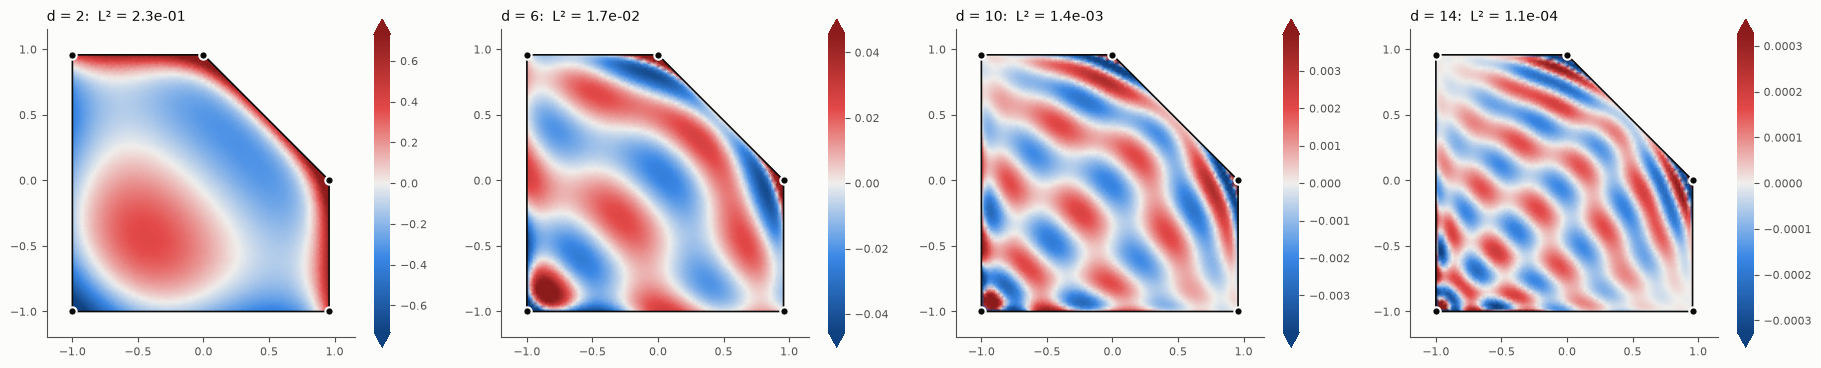

In [4]:
show = [2, 6, 10, 14]
fig, axes = plt.subplots(1, len(show), figsize=(4.6 * len(show), 4.4))
fig.patch.set_facecolor(viz.SURFACE)
for ax, d in zip(axes, show):
    viz.plot_field(results[d].metric, 'S - A_ext', ax=ax, resolution=80)
    ax.set_title(f"d = {d}:  L² = {results[d].defect_['L2']:.1e}", loc='left', fontsize=10, color=viz.INK)
fig.tight_layout()

### Convergence

Our defect against d, with Hall–Murphy's published L² errors (their Table 1, same measure) for comparison. Up to d ≈ 15 the two agree at every degree, although the functionals differ (theirs is ∫(S − A)², ours Donaldson's), which suggests both reach essentially the best approximation of that degree. After that their curve flattens, presumably the ill-conditioning of monomials, while ours stays geometric, as expected if h is real-analytic on a neighbourhood of P. Beyond d ≈ 24 ours stops improving too: evaluating the high-degree basis loses accuracy (see `solver.py`).

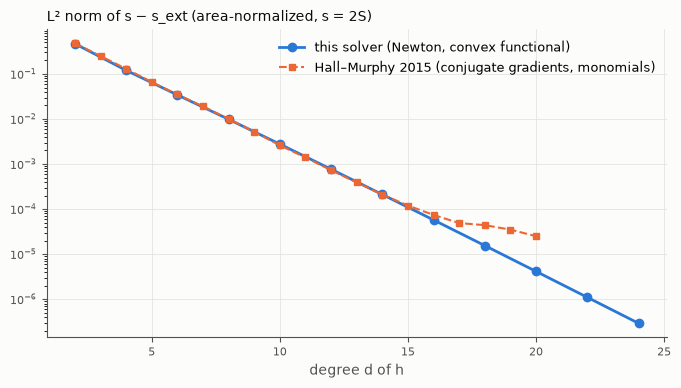

In [5]:
hm = {2: 0.48, 3: 0.25, 4: 0.13, 5: 0.066, 6: 0.035, 7: 0.019, 8: 0.010, 9: 0.0052, 10: 0.0026, 11: 0.0014,
      12: 7.3e-4, 13: 3.9e-4, 14: 2.1e-4, 15: 1.2e-4, 16: 7.4e-5, 17: 4.9e-5, 18: 4.4e-5, 19: 3.5e-5, 20: 2.5e-5}
ax = viz._line_axes(None, figsize=(8, 4))
ax.semilogy(degrees, [2 * results[d].defect_['L2'] for d in degrees], 'o-', color='#2a78d6', lw=2, ms=6,
            label='this solver (Newton, convex functional)')
ax.semilogy(list(hm), list(hm.values()), 's--', color='#eb6834', lw=1.5, ms=5,
            label='Hall–Murphy 2015 (conjugate gradients, monomials)')
ax.set_xlabel('degree d of h', color=viz.INK_2)
ax.set_title('L² norm of s − s_ext (area-normalized, s = 2S)', loc='left', fontsize=10, color=viz.INK)
ax.legend(frameon=False, fontsize=9);

### Coefficient decay

The largest coefficient of h in each degree (basis orthonormal on P), for the d = 24 solution. Geometric decay means h is analytic on a neighbourhood of P̄; the rate is set by the nearest singularity of h's analytic continuation. The last few degrees are at the round-off floor.

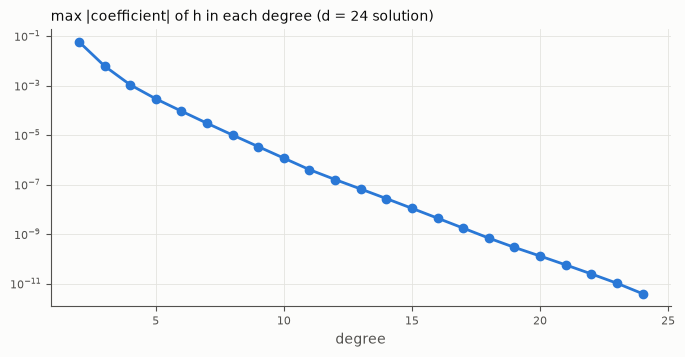

In [6]:
r = results[24]
deg = r.potential.basis.total_degree
c = r.potential.coeffs
ks = list(range(2, 25))
ax = viz._line_axes(None, figsize=(8, 3.6))
ax.semilogy(ks, [np.abs(c[deg == k]).max() for k in ks], 'o-', color='#2a78d6', lw=2, ms=6)
ax.set_xlabel('degree', color=viz.INK_2)
ax.set_title('max |coefficient| of h in each degree (d = 24 solution)', loc='left', fontsize=10, color=viz.INK);

## 3. The extremal metric

The d = 24 solution. S is A_ext (affine, as it must be), so the first panel is a plain ramp; |Ric|² and |Ric₀|² (traceless Ricci) are where the geometry shows.

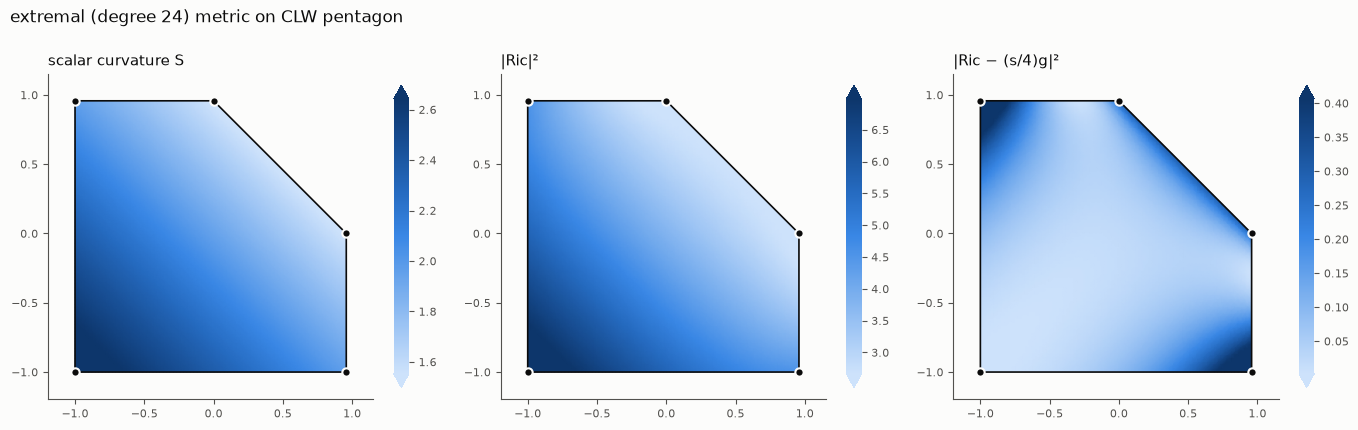

In [7]:
best = results[24].metric
viz.plot_fields(best, names=('S', '|Ric|^2', '|Ric_0|^2'), resolution=80);

## 4. Hall–Murphy's benchmarks

Write s = 2 A_ext and g_e = s⁻²g (the Einstein metric). Using only s and the polygon, Hall–Murphy (Prop. 2.3) give closed forms for ‖∇s‖² and ‖∇s⁻¹‖² in the metric g_e, and Lemma 2.4 gives κ, the scalar curvature of g_e. The numerical metric enters the same quantities only through uⁱʲ:

  ‖∇s‖² = (2π)² ∫ s⁻² |∇s|²_g dμ,   ‖∇s⁻¹‖² = (2π)² ∫ s⁻⁶ |∇s|²_g dμ,   with |∇s|²_g = uⁱʲ sᵢ sⱼ.

**These converge much faster than S − A_ext, and that is expected.** With f″(s) = s⁻², ∫ f″(s) uⁱʲ sᵢsⱼ dμ = ∫ uⁱʲ (f∘s)ᵢⱼ dμ = 2 L_{S(u)}(f∘s) by Donaldson's integration by parts. So the benchmark depends on the metric only through ∫ (S − A) f(s) dμ. At the solver's minimum, ∫ (S − A) φ dμ = 0 for every polynomial φ of degree ≤ d, so the error is (defect) × (how well the smooth function f∘s is approximated by polynomials): superconvergence. The benchmark confirms consistency with Hall–Murphy, but it is not an independent test of the metric; §5 is.

In [8]:
s_fn = lambda x, y: 2 * A(x, y)
I = lambda fn: 4 * np.pi**2 * integrate_numeric(P, fn, order=60)
vol_e = I(lambda x, y: s_fn(x, y)**-4)
calabi = I(lambda x, y: s_fn(x, y)**2)
chi, tau = 5, -1
kappa = 4 * np.sqrt((96 * np.pi**2 * chi + 144 * np.pi**2 * tau - calabi) / (8 * vol_e))
exact_g1 = I(lambda x, y: s_fn(x, y) - kappa * s_fn(x, y)**-2) / 6
exact_gm1 = -I(lambda x, y: s_fn(x, y)**-3 - kappa * s_fn(x, y)**-6) / 18
print(f'κ = {kappa:.8f}   Vol(g_e) = {vol_e:.10f}')
print(f'exact:  ‖∇s‖² = {exact_g1:.9f}   ‖∇s⁻¹‖² = {exact_gm1:.11f}   (Hall–Murphy: 4.9689665, 0.020806979)\n')

xq, yq, wq = polygon_quadrature(P, 50)
c1 = 2 * float(A.c1)   # ∂s/∂x = ∂s/∂y
print(f"{'d':>3} {'‖∇s‖²':>13} {'error':>9} {'‖∇s⁻¹‖²':>15} {'error':>9}")
for d in degrees[1:]:
    grad2, _ = results[d].metric.affine_gradient_and_laplacian(xq, yq, c1, c1)
    sq = s_fn(xq, yq)
    g1 = 4 * np.pi**2 * np.sum(wq * grad2 * sq**-2)
    gm1 = 4 * np.pi**2 * np.sum(wq * grad2 * sq**-6)
    print(f'{d:>3} {g1:>13.9f} {g1 - exact_g1:>9.1e} {gm1:>15.11f} {gm1 - exact_gm1:>9.1e}')

κ = 60.34566867   Vol(g_e) = 0.5834212453
exact:  ‖∇s‖² = 4.968966549   ‖∇s⁻¹‖² = 0.02080697966   (Hall–Murphy: 4.9689665, 0.020806979)

  d         ‖∇s‖²     error         ‖∇s⁻¹‖²     error
  4   4.968826864  -1.4e-04   0.02079974544  -7.2e-06
  6   4.968966058  -4.9e-07   0.02080690642  -7.3e-08


  8   4.968966547  -1.9e-09   0.02080697902  -6.5e-10


 10   4.968966549  -7.2e-12   0.02080697966  -5.1e-12


 12   4.968966549   1.9e-13   0.02080697966  -3.8e-14


 14   4.968966549   1.4e-11   0.02080697966   4.9e-14


 16   4.968966549   2.2e-13   0.02080697966  -7.6e-16


 18   4.968966549   1.3e-11   0.02080697966   4.8e-14


 20   4.968966549   2.2e-13   0.02080697966  -7.4e-16


 22   4.968966549   2.2e-13   0.02080697966  -7.2e-16


 24   4.968966549   2.2e-13   0.02080697966  -7.6e-16


## 5. The Einstein check

For a Kähler metric g with scalar curvature s ≠ 0, the conformal metric s⁻²g has scalar curvature s³ + 6 s Δs − 12 |∇s|² (Δ = div grad). For the CLW metric s⁻²g is Einstein, so this must be the constant κ (Derdziński; Hall–Murphy eq. 2.3). This is a genuinely new test: the solver only aims at S = A_ext, not at Bach-flatness, which holds because of the choice of Kähler class.

  d  L² (normalized)  relative to κ
  4         3.88e-01        6.4e-03
  6         8.40e-02        1.4e-03
  8         1.93e-02        3.2e-04
 10         4.55e-03        7.5e-05
 12         1.09e-03        1.8e-05
 14         2.63e-04        4.4e-06
 16         6.37e-05        1.1e-06


 18         1.55e-05        2.6e-07


 20         3.78e-06        6.3e-08
 22         9.22e-07        1.5e-08
 24         2.26e-07        3.7e-09


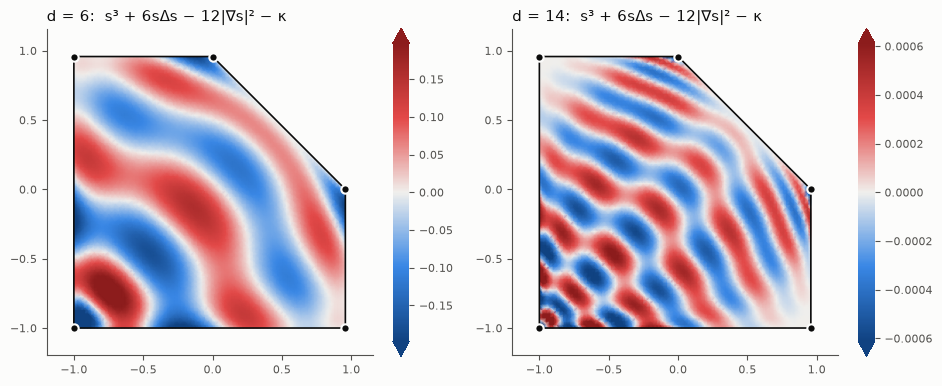

In [9]:
def einstein_defect(metric):
    def fn(x, y):
        grad2, lap = metric.affine_gradient_and_laplacian(x, y, c1, c1)
        s = s_fn(x, y)
        return s**3 + 6 * s * lap - 12 * grad2 - kappa
    return fn

print(f"{'d':>3} {'L² (normalized)':>16} {'relative to κ':>14}")
for d in degrees[1:]:
    e = einstein_defect(results[d].metric)(xq, yq)
    l2 = np.sqrt(np.sum(wq * e**2) / np.sum(wq))
    print(f'{d:>3} {l2:>16.2e} {l2 / kappa:>14.1e}')

fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.4))
fig.patch.set_facecolor(viz.SURFACE)
for ax, d in zip(axes, (6, 14)):
    viz.plot_function(P, einstein_defect(results[d].metric), ax=ax, diverging=True, resolution=80,
                      label=f'd = {d}:  s³ + 6sΔs − 12|∇s|² − κ')
fig.tight_layout()

## Still to do

- The full Einstein check: the traceless Ricci tensor of s⁻²g, not just its scalar curvature.
- Higher degree: beyond d ≈ 24 the basis evaluation loses accuracy; extended precision or a basis on triangles would push further.